# 5. Línea base estadística

Con las 15 corridas terminadas, el siguiente paso fue evaluar las redes Mask R-CNN, YOLOv8-seg y SOLOv2. Aquí se presentan las métricas utilizadas, el desempeño de cada una en el conjunto de prueba y su comparación mediante pruebas estadísticas que toman el grupo de escena como unidad de análisis.

En la celda siguiente se cargan las rutas y funciones del proyecto. No se entrena nada: las tablas y figuras se obtienen de los resultados guardados de las 15 corridas.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Image, Markdown
from itertools import combinations
import estadistica_instancias as EI

LIT = ROOT / 'literatura' / 'instancias'
CORR = ROOT / 'results' / 'instancias' / 'corridas'
MODELOS = {'maskrcnn': 'Mask R-CNN', 'yolov8seg': 'YOLOv8-seg', 'solov2': 'SOLOv2'}
orden = ['maskrcnn', 'yolov8seg', 'solov2']
pd.set_option('display.max_colwidth', 90)
print('Corridas encontradas:', sorted(p.name for p in CORR.glob('*_s*') if (p / 'metricas.json').exists()))

Corridas encontradas: ['maskrcnn_s42', 'maskrcnn_s43', 'maskrcnn_s44', 'maskrcnn_s45', 'maskrcnn_s46', 'solov2_s42', 'solov2_s43', 'solov2_s44', 'solov2_s45', 'solov2_s46', 'yolov8seg_s42', 'yolov8seg_s43', 'yolov8seg_s44', 'yolov8seg_s45', 'yolov8seg_s46']


## 5.1 Métricas

- **Métrica primaria: F1 de instancia por imagen.** En cada imagen se emparejan predicciones y tornillos reales con el algoritmo húngaro. Una pareja cuenta como acierto (TP) si su IoU de máscara es de al menos 0.5. La métrica se calcula como $$F1 = \frac{2TP}{2TP + FP + FN},$$ donde FP son las predicciones sin pareja y FN los tornillos reales sin detectar.
- **Secundarias:**
  - PQ (*panoptic quality*) = SQ × F1, donde SQ es el IoU medio de los aciertos;
  - AP50 de máscara.
- **Informativa:** AP de máscara promediado en IoU de 0.5 a 0.95, el estándar de COCO.
- **Umbral práctico:** δ = 0.20 puntos de F1.

**Referencia física para el margen.** Ku y Chen estudian el atornillado robótico de un tornillo M6. Su análisis estima un error mecánico de posicionamiento de aproximadamente 0,2 mm; en las pruebas, el mecanismo permitió compensar desalineaciones iniciales y completar más del 80 % de las secuencias cuando el desajuste era menor de 3 mm ([Ku y Chen, 2022](https://doi.org/10.5194/ms-13-701-2022)). El caso de un solo tornillo muestra por qué la alineación y el acoplamiento entre herramienta y cabeza importan físicamente.

Tomamos ese análisis como referencia para fijar δ = 0.20 como una barrera exigente de mejora en la detección antes de considerar un modelo más complejo. Las magnitudes no son equivalentes: el estudio expresa error de posición en milímetros, mientras que aquí δ representa 0,20 puntos de F1. El paper motiva la relevancia práctica de localizar bien un tornillo, pero no establece una conversión entre milímetros, F1 y éxito de desmontaje. Esa relación requeriría calibración píxel–milímetro y pruebas de extremo a extremo con el robot y la herramienta.


## 5.2 Resultados por modelo

**Tabla 5.1.** Desempeño en prueba: media, desviación estándar e intervalo de confianza del 95 % (t de Student) sobre las 5 semillas.

In [9]:
res = EI.analizar(CORR)  # imprime también el detalle; se resume abajo

== Resumen por modelo (test, sobre semillas)
            n_semillas  F1_img_media  F1_img_de  F1_grupo_media  PQ_img_media  PQ_img_de  PQ_grupo_media  PQ_grupo_de  AP_media   AP_de  AP50_media  F1_img_ic95  PQ_img_ic95  AP_ic95
modelo                                                                                                                                                                               
maskrcnn            5        0.4467     0.0173          0.7259        0.3133     0.0108          0.5250       0.0116    0.2168  0.0039      0.5871       0.0215       0.0134   0.0048
solov2              5        0.2967     0.0267          0.2692        0.2104     0.0170          0.1950       0.0162    0.1127  0.0053      0.2849       0.0332       0.0211   0.0066
yolov8seg           5        0.5208     0.0613          0.7345        0.3652     0.0398          0.5138       0.0194    0.2344  0.0082      0.6373       0.0761       0.0494   0.0101 

== f1 por grupo (n = 14 grupos)
 modelo  m

In [10]:
_, runs = EI.cargar(CORR)
def ic(x):
    h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return f'{x.mean():.3f} ± {x.std(ddof=1):.3f} [{x.mean() - h:.3f}, {x.mean() + h:.3f}]'
tabla51 = runs.groupby('modelo').agg(n=('semilla', 'nunique'), F1_img=('F1_img', ic), PQ_img=('PQ_img', ic),
                                      AP50=('AP50', ic), AP=('AP', ic)).rename(index=MODELOS)
display(tabla51)

,n,F1_img,PQ_img,AP50,AP
modelo,,,,,
Mask R-CNN,5,"0.447 ± 0.017 [0.425, 0.468]","0.313 ± 0.011 [0.300, 0.327]","0.587 ± 0.010 [0.575, 0.599]","0.217 ± 0.004 [0.212, 0.222]"
SOLOv2,5,"0.297 ± 0.027 [0.263, 0.330]","0.210 ± 0.017 [0.189, 0.231]","0.285 ± 0.017 [0.264, 0.306]","0.113 ± 0.005 [0.106, 0.119]"
YOLOv8-seg,5,"0.521 ± 0.061 [0.445, 0.597]","0.365 ± 0.040 [0.316, 0.415]","0.637 ± 0.019 [0.614, 0.661]","0.234 ± 0.008 [0.224, 0.245]"


**Tabla 5.2.** Conteos agregados en prueba (5 semillas × 108 imágenes): de dónde sale cada F1.

In [11]:
imgs, _ = EI.cargar(CORR)
cont = imgs.groupby('modelo')[['tp', 'fp', 'fn', 'n_gt', 'n_pred']].sum()
cont['precisión'] = (cont.tp / cont.n_pred).round(3)
cont['recall'] = (cont.tp / cont.n_gt).round(3)
display(cont.rename(index=MODELOS))

,tp,fp,fn,n_gt,n_pred,precisión,recall
modelo,,,,,,,
Mask R-CNN,1132,742,813,1945,1874,0.604,0.582
SOLOv2,595,410,1350,1945,1005,0.592,0.306
YOLOv8-seg,1220,706,725,1945,1926,0.633,0.627


## 5.3 Comparación estadística

**Unidad de análisis.** La unidad de independencia es el grupo, no la imagen, porque las imágenes de una misma sesión están correlacionadas. Para cada modelo y grupo de prueba se promedia el F1 de las imágenes del grupo y luego el de las semillas. Resulta una tabla de 14 grupos × 3 modelos.

**Pruebas.**
1. **Friedman** sobre los tres modelos, con los grupos como bloques. Prueba si al menos un modelo difiere de los otros.
2. **Wilcoxon pareado por grupo** para cada par de modelos, con corrección de Holm por los 3 contrastes.
3. **Intervalo bootstrap del 95 %** de la diferencia media por par, remuestreando grupos (10 000 réplicas).
4. **Efecto mínimo detectable (MDE)** de cada par, con el alfa de Holm y potencia 0.80. Si el MDE es mayor que δ, la prueba no tiene potencia para detectar una diferencia práctica, y un resultado no significativo se reporta como no concluyente, no como empate.

**Tabla 5.3.** F1 medio por grupo de prueba (promedio de las imágenes del grupo y luego de las 5 semillas).

In [12]:
g = res['por_grupo'].rename(columns=MODELOS)
n_img = imgs.drop_duplicates('archivo').groupby('grupo').size().rename('imágenes')
display(g.join(n_img).round(3))
print(f"Friedman: chi2 = {res['friedman']['estadistico']:.2f}, p = {res['friedman']['p']:.4f}")

,Mask R-CNN,SOLOv2,YOLOv8-seg,imágenes
grupo,,,,
6,0.291,0.000,0.239,15
9,0.018,0.000,0.224,28
12,0.681,0.648,0.665,15
27,0.725,0.733,0.760,13
32,0.560,0.328,0.823,16
45,0.764,0.000,0.705,1
58,0.941,0.105,0.933,1
69,0.948,0.715,0.918,1
77,0.882,0.164,0.764,1


Friedman: chi2 = 16.62, p = 0.0002


**Figura 5.1.** F1 por grupo de prueba. Cada línea une los tres modelos en un mismo grupo; el tamaño del punto es proporcional al número de imágenes del grupo.

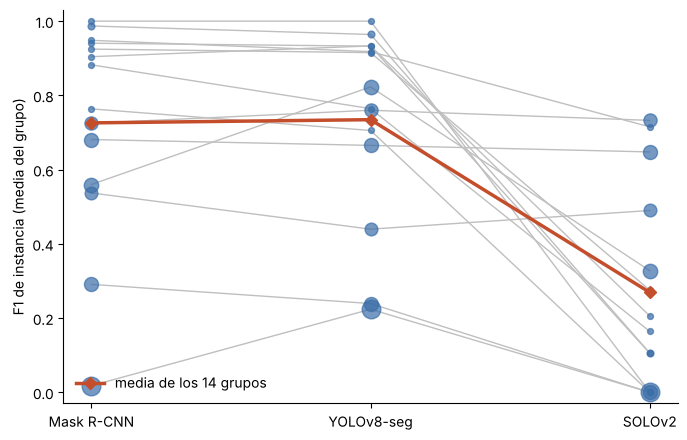

In [13]:
orden = ['maskrcnn', 'yolov8seg', 'solov2']
gg = res['por_grupo'][orden]
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(orden))
for grupo, fila in gg.iterrows():
    ax.plot(x, fila.values, color='0.75', lw=1, zorder=1)
    ax.scatter(x, fila.values, s=12 + 6 * n_img[grupo], color='#3b6ea8', alpha=0.7, zorder=2)
ax.plot(x, gg.mean().values, color='#c44e2b', lw=2.5, marker='D', label='media de los 14 grupos', zorder=3)
ax.set_xticks(x, [MODELOS[m] for m in orden])
ax.set_ylabel('F1 de instancia (media del grupo)')
ax.set_ylim(-0.03, 1.03)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower left')
plt.tight_layout(); plt.show()

**Tabla 5.4.** Contrastes por pares (unidad = grupo, n = 14; Wilcoxon pareado con corrección de Holm, IC95 bootstrap remuestreando grupos, MDE con potencia 0.80).

In [14]:
pares = res['pares'].copy()
for k, v in MODELOS.items():
    pares['par'] = pares['par'].str.replace(k, v)
display(pares.round(4))

,par,dif_media,de_dif,ic95_boot_grupos,wilcoxon_W,p,gana_a_en_grupos,p_holm,MDE,supera_delta
0,Mask R-CNN - SOLOv2,0.4567,0.3679,"(0.2683, 0.6393)",1.0,0.0002,13,0.0007,0.3556,True
1,Mask R-CNN - YOLOv8-seg,-0.0086,0.1052,"(-0.0655, 0.0389)",37.0,0.5525,9,0.5525,0.1017,False
2,SOLOv2 - YOLOv8-seg,-0.4653,0.3491,"(-0.6408, -0.2846)",3.0,0.0006,1,0.0012,0.3374,True


Con PQ como métrica secundaria:

In [15]:
res_pq = EI.analizar(CORR, metrica='pq')

== Resumen por modelo (test, sobre semillas)
            n_semillas  F1_img_media  F1_img_de  F1_grupo_media  PQ_img_media  PQ_img_de  PQ_grupo_media  PQ_grupo_de  AP_media   AP_de  AP50_media  F1_img_ic95  PQ_img_ic95  AP_ic95
modelo                                                                                                                                                                               
maskrcnn            5        0.4467     0.0173          0.7259        0.3133     0.0108          0.5250       0.0116    0.2168  0.0039      0.5871       0.0215       0.0134   0.0048
solov2              5        0.2967     0.0267          0.2692        0.2104     0.0170          0.1950       0.0162    0.1127  0.0053      0.2849       0.0332       0.0211   0.0066
yolov8seg           5        0.5208     0.0613          0.7345        0.3652     0.0398          0.5138       0.0194    0.2344  0.0082      0.6373       0.0761       0.0494   0.0101 

== pq por grupo (n = 14 grupos)
 modelo  m

### Supuestos, tamaño de efecto y diferencia relativa

**Tabla 5.5.** Por par y sobre los 14 grupos:
- Shapiro–Wilk de las diferencias pareadas;
- t pareado, como contraste paramétrico de referencia;
- d de Cohen pareada (media/DE de las diferencias);
- r biserial de rangos (el tamaño de efecto del Wilcoxon);
- probabilidad de superioridad (fracción de grupos donde gana el primero, con empates a la mitad);
- diferencia relativa respecto al segundo modelo del par.

In [16]:
g = res['por_grupo']
filas = []
for a, b in combinations(sorted(g.columns), 2):
    dif = (g[a] - g[b]).to_numpy()
    nz = dif[dif != 0]; rk = stats.rankdata(np.abs(nz))
    wp, wm = rk[nz > 0].sum(), rk[nz < 0].sum()
    filas.append({'par': f'{MODELOS[a]} − {MODELOS[b]}', 'dif. media': dif.mean(),
                  'dif. relativa (%)': 100 * dif.mean() / g[b].mean(),
                  'Shapiro–Wilk p': stats.shapiro(dif).pvalue, 't pareado p': stats.ttest_rel(g[a], g[b]).pvalue,
                  'd de Cohen pareada': dif.mean() / dif.std(ddof=1), 'r biserial': (wp - wm) / (wp + wm),
                  'P(superioridad)': ((dif > 0).sum() + 0.5 * (dif == 0).sum()) / len(dif)})
efectos = pd.DataFrame(filas)
display(efectos.round(4))

,par,dif. media,dif. relativa (%),Shapiro–Wilk p,t pareado p,d de Cohen pareada,r biserial,P(superioridad)
0,Mask R-CNN − SOLOv2,0.4567,169.6418,0.0586,0.0005,1.2412,0.9810,0.9286
1,Mask R-CNN − YOLOv8-seg,-0.0086,-1.1762,0.0085,0.7635,-0.0821,0.1868,0.6786
2,SOLOv2 − YOLOv8-seg,-0.4653,-63.3500,0.2970,0.0002,-1.3331,-0.9429,0.0714


**Figura 5.2.** Gráficos Q–Q de las diferencias por grupo de cada par.

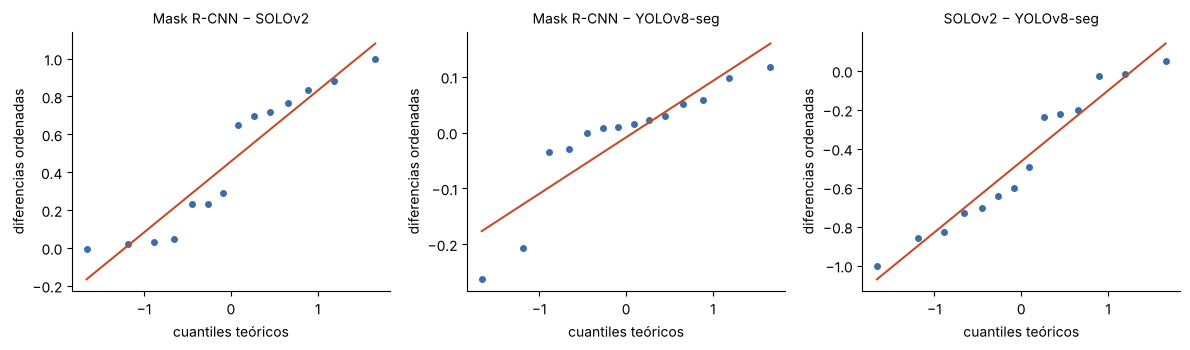

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for k, (a, b) in enumerate(combinations(sorted(g.columns), 2)):
    stats.probplot(g[a] - g[b], dist='norm', plot=ax[k])
    ax[k].set_title(f'{MODELOS[a]} − {MODELOS[b]}', fontsize=10)
    ax[k].get_lines()[0].set(markersize=4, color='#3b6ea8'); ax[k].get_lines()[1].set(color='#c44e2b')
    ax[k].set_xlabel('cuantiles teóricos'); ax[k].set_ylabel('diferencias ordenadas')
    ax[k].spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Descomposición de la varianza.** Hay dos niveles:
- **Entre las 15 corridas:** qué parte de la varianza del F1 por imagen en prueba se debe al modelo y qué parte a la semilla.
- **En la tabla de 14 grupos × 3 modelos:** qué parte se debe al grupo (la escena), qué parte al modelo y qué parte a la interacción con el residuo.

In [18]:
gm = runs.F1_img.mean()
ss_tot = ((runs.F1_img - gm) ** 2).sum()
ss_mod = runs.groupby('modelo').F1_img.apply(lambda v: len(v) * (v.mean() - gm) ** 2).sum()
print(f'Corridas: modelo {100 * ss_mod / ss_tot:.1f} %, semilla {100 * (1 - ss_mod / ss_tot):.1f} % de la suma de cuadrados')
G = g.to_numpy(); m0 = G.mean(); n_g, k_m = G.shape
ss_t = ((G - m0) ** 2).sum()
ss_g = k_m * ((G.mean(1) - m0) ** 2).sum(); ss_m = n_g * ((G.mean(0) - m0) ** 2).sum()
print(f'Grupos x modelos: grupo {100 * ss_g / ss_t:.1f} %, modelo {100 * ss_m / ss_t:.1f} %, '
      f'interacción y residuo {100 * (ss_t - ss_g - ss_m) / ss_t:.1f} %')

Corridas: modelo 87.2 %, semilla 12.8 % de la suma de cuadrados
Grupos x modelos: grupo 36.0 %, modelo 40.3 %, interacción y residuo 23.6 %


**Lectura de los supuestos y efectos.**
- **Mask R-CNN − YOLOv8-seg.** Shapiro–Wilk rechaza la normalidad (p = 0.009). En el Q–Q hay dos grupos donde YOLOv8-seg gana por mucho (diferencias de −0.21 y −0.26) y que se salen de la recta. Eso justifica usar Wilcoxon como prueba principal en vez de t pareado; el t pareado da la misma conclusión (p = 0.76).
- **Efecto pequeño y de signo ambiguo.** La d pareada es −0.08 (casi nula), pero el r biserial es +0.19 y la probabilidad de superioridad 0.68. Mask R-CNN gana en más grupos, pero por poco, mientras que YOLOv8-seg gana por más en los grupos donde gana. Las dos lecturas apuntan a lo mismo: ninguno domina.
- **Los contrastes con SOLOv2** tienen efectos grandes en cualquier escala: |d| ≥ 1.2, |r| ≥ 0.94, probabilidad de superioridad de 0.93 y 0.07. En diferencia relativa, SOLOv2 queda un 63 % por debajo de YOLOv8-seg en F1 por grupo.
- **Varianza entre corridas.** El modelo explica la mayor parte (≈ 87 %); la semilla aporta poco.
- **Varianza por grupo.** El grupo pesa casi tanto como el modelo (36 % frente a 40 %): la escena cambia el resultado tanto como cambiar de arquitectura. Es otra razón para usar el grupo como unidad de inferencia y para ampliar la prueba con más escenas en el E2.

No se afirma equivalencia entre Mask R-CNN y YOLOv8-seg. Para hacerlo haría falta un TOST con margen δ, y con un MDE de 0.10 no tendría potencia.

**Lectura.**
- **SOLOv2 queda por debajo de los otros dos** con una diferencia grande (≈0.46 en F1 por grupo), muy por encima de δ = 0.20 y significativa tras Holm. Pierde en 13 de los 14 grupos frente a cada uno de los otros modelos. La tabla 5.2 muestra de dónde viene: su precisión es similar a la de los otros (0.59 frente a 0.60–0.63), pero su recall es la mitad (0.31 frente a 0.58–0.63). Deja de detectar la mitad de los tornillos. Una explicación plausible, no verificada con un experimento, es su forma de asignar objetos: SOLOv2 decide la presencia de una instancia en una cuadrícula de 40 × 40 celdas, que a 1280 px son celdas de unos 32 px, mientras que el tornillo mediano mide 12 px.
- **Mask R-CNN y YOLOv8-seg no se distinguen con estos datos.** La diferencia por grupo es de −0.009 (IC95 [−0.066, 0.039]; p de Holm = 0.55). La diferencia observada (0.009) es menor que δ = 0.20. El IC95 [−0.066, 0.039] también queda dentro de ese margen; no se realizó una prueba TOST para afirmar equivalencia formal.
- **La media por imagen y la media por grupo cuentan historias distintas.** Por imagen, YOLOv8-seg supera a Mask R-CNN (0.52 frente a 0.45), pero buena parte de esa ventaja viene del grupo 9, que tiene 28 de las 108 imágenes de prueba: allí Mask R-CNN casi no acierta (F1 0.02) y YOLOv8-seg llega a 0.22. Al usar el grupo como unidad, ese grupo pesa lo mismo que los demás y la ventaja desaparece. Por eso la conclusión se apoya en el análisis por grupo.
- **El reparto entre máquinas no cambia el patrón.** Las semillas de la RTX 3050 (45 y 46) quedan en el mismo rango que las de la RTX 3060 en F1 por imagen: Mask R-CNN 0.450 y 0.461 frente a 0.418–0.458; YOLOv8-seg 0.568 y 0.504 frente a 0.429–0.584; SOLOv2 0.305 y 0.287 frente a 0.256–0.326. Lo que cambia es el tiempo de cómputo.

## 5.4 Baseline y margen de mejora

- **Baseline de referencia.** Por imagen, el mejor modelo base es **YOLOv8-seg**: F1 de instancia de 0.521 ± 0.061, IC95 [0.445, 0.597] con t de Student sobre 5 semillas. Por grupo no se distingue de Mask R-CNN (0.735 frente a 0.726). El baseline que hereda el E2 es, por lo tanto, el nivel de los dos mejores modelos base:
  - **F1 por imagen ≈ 0.52** (YOLOv8-seg);
  - **F1 por grupo ≈ 0.73**.

  Se toma YOLOv8-seg como modelo de referencia porque tiene el mejor F1 por imagen y la menor complejidad: 3.3 M parámetros frente a 44 M de Mask R-CNN, y el menor tiempo por corrida.
- **Umbral de mejora para un modelo avanzado.** La mejora debe ser de al menos δ = 0.20 puntos de F1. Con el baseline por imagen de 0.521, esto corresponde a un F1 de al menos 0.721. El MDE actual por grupos es ≈ 0.10; en el E2 debe recalcularse con sus comparaciones y grupos.
- **Cota de referencia.** El acuerdo entre las dos versiones de la anotación del dataset (máscaras PNG frente a polígonos COCO) da un F1 de instancia de 0.9995 a IoU 0.5 (`techo_anotacion` en la declaración a priori). Con esto, el ruido de etiqueta no limita la métrica primaria, y el margen disponible sobre el baseline es amplio: ≈ 0.48 en F1 por imagen.
- **Complejidad frente a desempeño.** Mayor complejidad no da mejor resultado. El modelo más pequeño (YOLOv8-seg, 3.3 M) iguala o supera al de dos etapas (Mask R-CNN, 44 M) y supera con amplitud a SOLOv2 (46 M). Lo que pesa es si la arquitectura resuelve objetos de unos 11 px, no el tamaño del modelo.

## 5.5 Limitaciones

- **Pocos grupos en prueba.** Hay 14, y 8 de ellos tienen una o dos imágenes (7 con una sola). Eso limita la potencia: con Wilcoxon exacto y 14 pares, el p más pequeño posible es del orden de 10⁻⁴, pero detectar diferencias moderadas exige que un modelo gane en casi todos los grupos.
- **Marcos distintos.** SOLOv2 corre en MMDetection, con torch 2.1.2, porque mmcv 2.1 solo tiene versiones precompiladas para Windows con torch 2.1. Mask R-CNN y YOLOv8-seg usan torch 2.11. La evaluación es idéntica para los tres (el mismo código de métricas sobre las predicciones exportadas en formato COCO), pero las rutinas de entrenamiento no son idénticas.
- **Aumento de datos distinto.** Cada modelo conserva el aumento de datos de su receta, y YOLOv8-seg entrena con aumentos más fuertes que los otros dos. Parte de su ventaja por imagen puede venir de ahí.
- **Presupuesto fijo de épocas.** 12/40/12 épocas por limitaciones de tiempo y GPU (6 GB). Un modelo que converja más lento queda en desventaja.
- **No determinismo de GPU.** Con la misma semilla, cuDNN no garantiza resultados idénticos. La variación entre semillas incluye ese ruido.
- **Piloto a posteriori.** El dimensionamiento de la sección 4.5 se hizo con las corridas definitivas, no antes, y no hubo prerregistro fechado previo a la ejecución. El margen práctico δ = 0.20 se seleccionó tras las corridas base para evaluar modelos avanzados; no se fijó antes de comparar los tres modelos base.
- **Pruebas que comparten el conjunto de prueba.** Las 5 semillas de un modelo se evalúan en las mismas 108 imágenes, así que no son observaciones independientes. Por eso la inferencia se hace sobre grupos y no sobre corridas.
- **Tiempo de inferencia no medido.** Solo se registró el tiempo total por corrida (tabla 4.3), que incluye la validación de cada época.
- **Sin análisis cualitativo ni de robustez por tamaño.** No se incluye la visualización de predicciones frente a la verdad ni el desempeño por tamaño de tornillo. Las predicciones están guardadas (`preds_test.json`), así que el análisis se puede hacer sin reentrenar; queda para el E2.